# 03 — Final model

LightGBM configuration chosen on the full training set, then evaluated once on each test set.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
from src.data import RESULTS_DIR
from src import plots

RECOMPUTE = False  # True: recalculate everything instead of loading saved results (~60 min)

In [2]:
if RECOMPUTE:
    import joblib
    from src.data import load_all, to_3_classes, cv_folds
    from src.models import MODELS, fit_lightgbm
    from src.evaluation import compare_models, load_configs
    from src.final_model import (choose_lightgbm_config, save_final_params, evaluate_on_test,
                                 four_class_reference, FINAL_MODEL_PATH)
    df = load_all()
    train = df[df['split'] == 'train'].reset_index(drop=True)
    y = to_3_classes(train['Severity'].to_numpy())
    folds = cv_folds(train)

    # 1. The 3 best LightGBM configurations from the sample, checked on the full training set
    table, params, lgbm_per_fold, _ = choose_lightgbm_config(train, y, folds)
    table.to_csv(f'{RESULTS_DIR}/full_train_cv_lightgbm.csv', index=False)
    save_final_params(params)

    # 2. Best RF and best neural network on the same folds, for a full-data comparison
    others = {name: (MODELS[name], load_configs(name)[0]) for name in ['random_forest', 'neural_net']}
    other_per_fold, _, _ = compare_models(train, y, folds, others)
    pd.concat([lgbm_per_fold, other_per_fold]).to_csv(
        f'{RESULTS_DIR}/full_train_cv_per_fold.csv', index=False)

    # 3. Final model on the whole training set, evaluated once on each test set
    model = fit_lightgbm(train, y, params)
    joblib.dump(model, FINAL_MODEL_PATH)
    tests = {}
    for part in ['test_in', 'test_out']:
        test = df[df['split'] == part].reset_index(drop=True)
        tests[part] = test
        res = evaluate_on_test(model, test, to_3_classes(test['Severity'].to_numpy()))
        res['metrics'].to_csv(f'{RESULTS_DIR}/test_{part}_metrics.csv')
        res['by_source'].to_csv(f'{RESULTS_DIR}/test_{part}_by_source.csv')
        res['by_year'].to_csv(f'{RESULTS_DIR}/test_{part}_by_year.csv')
        res['confusion'].to_csv(f'{RESULTS_DIR}/test_{part}_confusion.csv')
    four_class_reference(train, tests, params).to_csv(f'{RESULTS_DIR}/test_4class_auxiliary.csv')

## Choosing the configuration (full training set)

In [3]:
pd.read_csv(f'{RESULTS_DIR}/full_train_cv_lightgbm.csv')

,weight_power,subsample_freq,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,macro_f1_mean,macro_f1_std,qwk_mean,seconds
0,1.0,1,0.8,0.0,127,200,20,0.05,1.0,0.603,7.269e-04,0.381,149.338
1,0.5,1,0.8,0.0,63,400,100,0.03,0.8,0.676,4.759e-03,0.715,198.742
2,0.5,1,0.8,5.0,127,800,50,0.05,0.8,0.726,5.501e-03,0.757,375.870


## LightGBM vs Random Forest vs neural network (full training set, same folds)

In [4]:
per_fold = pd.read_csv(f'{RESULTS_DIR}/full_train_cv_per_fold.csv')
metrics = ['macro_f1', 'balanced_acc', 'qwk', 'recall_Sev1-2', 'recall_Sev3', 'recall_Sev4']
per_fold.groupby('model')[metrics].agg(['mean', 'std']).sort_values(('macro_f1', 'mean'), ascending=False)

macro_f1        balanced_acc           qwk        recall_Sev1-2  \
                  mean    std         mean    std   mean    std          mean   
model                                                                           
lightgbm         0.726  0.006        0.723  0.006  0.757  0.002         0.949   
random_forest    0.717  0.003        0.740  0.006  0.740  0.002         0.943   
neural_net       0.617  0.004        0.639  0.008  0.605  0.004         0.907   

                         recall_Sev3            recall_Sev4         
                     std        mean        std        mean    std  
model                                                               
lightgbm       4.728e-04       0.876  6.235e-04       0.343  0.018  
random_forest  4.992e-04       0.878  7.275e-04       0.399  0.017  
neural_net     2.612e-03       0.809  4.690e-03       0.200  0.020

In [5]:
# Paired comparison: LightGBM minus Random Forest in each fold
wide = per_fold.pivot(index='fold', columns='model', values='macro_f1')
(wide['lightgbm'] - wide['random_forest']).rename('macro-F1 difference (LightGBM - RF)')

fold
0    0.012
1    0.011
2    0.011
3    0.004
4    0.009
Name: macro-F1 difference (LightGBM - RF), dtype: float64

In [6]:
# Parameters of the final model
from src.final_model import load_final_params
load_final_params()

{'weight_power': 0.5,
 'subsample_freq': 1,
 'subsample': 0.8,
 'reg_lambda': 5.0,
 'num_leaves': 127,
 'n_estimators': 800,
 'min_child_samples': 50,
 'learning_rate': 0.05,
 'colsample_bytree': 0.8}

## Test results (95% bootstrap interval)

In [7]:
test_in = pd.read_csv(f'{RESULTS_DIR}/test_test_in_metrics.csv', index_col=0)
test_out = pd.read_csv(f'{RESULTS_DIR}/test_test_out_metrics.csv', index_col=0)
pd.concat({'test_in (2016–2021)': test_in, 'test_out (2022–2023)': test_out}, axis=1)

test_in (2016–2021)                test_out (2022–2023)         \
                            value ci_low ci_high                value ci_low   
macro_f1                    0.735  0.727   0.742            5.905e-01  0.589   
balanced_acc                0.740  0.731   0.748            6.343e-01  0.633   
qwk                         0.760  0.756   0.765            5.161e-01  0.508   
recall_Sev1-2               0.949  0.948   0.950            9.877e-01  0.987   
recall_Sev3                 0.877  0.874   0.880            9.149e-01  0.910   
recall_Sev4                 0.392  0.367   0.417            2.974e-04  0.000   

                          
                 ci_high  
macro_f1       5.923e-01  
balanced_acc   6.358e-01  
qwk            5.238e-01  
recall_Sev1-2  9.880e-01  
recall_Sev3    9.197e-01  
recall_Sev4    9.086e-04

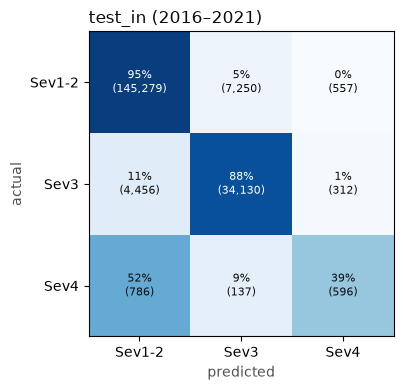

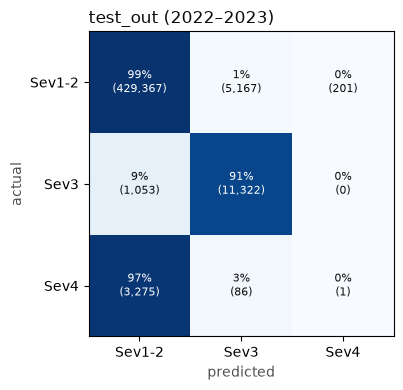

In [8]:
for part, title in [('test_in', 'test_in (2016–2021)'), ('test_out', 'test_out (2022–2023)')]:
    confusion = pd.read_csv(f'{RESULTS_DIR}/test_{part}_confusion.csv', index_col=0)
    plots.confusion_heatmap(confusion, title=title)

## By data source and by year

On 2022–2023 the model misses almost all Sev4 accidents.

In [9]:
pd.concat({'test_in': pd.read_csv(f'{RESULTS_DIR}/test_test_in_by_source.csv', index_col=0),
           'test_out': pd.read_csv(f'{RESULTS_DIR}/test_test_out_by_source.csv', index_col=0)})

macro_f1  balanced_acc        qwk  recall_Sev1-2  \
test_in  Source1     0.523         0.506  4.344e-01          0.993   
         Source2     0.604         0.608  7.952e-01          0.871   
         Source3     0.584         0.597  7.542e-01          0.847   
test_out Source1     0.332         0.500 -3.465e-04          1.000   
         Source2     0.544         0.563  6.380e-01          0.774   
         Source3     0.571         0.597  7.182e-01          0.880   

                  recall_Sev3  recall_Sev4         n  
test_in  Source1        0.101    4.235e-01  103441.0  
         Source2        0.944    9.091e-03   83197.0  
         Source3        0.944    0.000e+00    6865.0  
test_out Source1        0.000    3.059e-04  413496.0  
         Source2        0.915    0.000e+00   32312.0  
         Source3        0.910    0.000e+00    4664.0

In [10]:
pd.concat({'test_in': pd.read_csv(f'{RESULTS_DIR}/test_test_in_by_year.csv', index_col=0),
           'test_out': pd.read_csv(f'{RESULTS_DIR}/test_test_out_by_year.csv', index_col=0)})

macro_f1  balanced_acc        qwk  recall_Sev1-2  recall_Sev3  \
test_in  2016     0.756         0.801  7.738e-01          0.923        0.897   
         2017     0.764         0.809  7.810e-01          0.928        0.894   
         2018     0.750         0.780  7.701e-01          0.925        0.887   
         2019     0.730         0.702  7.384e-01          0.944        0.858   
         2020     0.677         0.664  6.318e-01          0.962        0.784   
         2021     0.636         0.670  6.648e-01          0.962        0.912   
test_out 2022     0.590         0.633  5.272e-01          0.985        0.915   
         2023     0.333         0.500 -8.777e-04          0.999        0.000   

               recall_Sev4       n  
test_in  2016    5.833e-01   20988  
         2017    6.066e-01   22994  
         2018    5.282e-01   23510  
         2019    3.048e-01   31998  
         2020    2.456e-01   42637  
         2021    1.347e-01   51376  
test_out 2022    3.197e-04  375913  
         2023    0.000e+00   74559

## 4-class result (only for comparison with v1)

In [11]:
pd.read_csv(f'{RESULTS_DIR}/test_4class_auxiliary.csv', index_col=0)

,macro_f1,balanced_acc,qwk,recall_Sev1,recall_Sev2,recall_Sev3,recall_Sev4
test_in,0.694,0.723,0.758,0.677,0.945,0.878,0.391
test_out,0.442,0.475,0.426,0.000,0.984,0.917,0.000
